# Saudi Hourly Weather & Solar Data: Summary Report
CS316 project, data quality summary. Run the cells **top to bottom**.

**Before you start:** run the download cell to get the eight city CSV files. If you already extracted them under `openmeteo_history/`, skip that cell.

## 1. Setup

In [415]:
# ---------------------------------------------------------------
# CELL 1: SETUP
# Imports the library and defines the lists the later cells use.
# Run this first. It produces no output.
# ---------------------------------------------------------------
import pandas as pd

# Column groups: weather variables and solar radiation variables
WEATHER = ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "surface_pressure",
           "wind_speed_10m", "wind_direction_10m", "cloud_cover", "precipitation"]
SOLAR = ["shortwave_radiation",        # GHI (global horizontal irradiance), W/m2 - main solar target
         "direct_radiation",           # direct radiation on a horizontal surface, W/m2
         "diffuse_radiation",          # DHI (diffuse radiation), W/m2
         "direct_normal_irradiance"]   # DNI (direct beam), W/m2

# Physically plausible (min, max) for each variable; used by the range check in cell 8
RANGES = {"temperature_2m": (-50, 55),          # degrees C
          "relative_humidity_2m": (0, 100),     # %
          "surface_pressure": (700, 1100),      # hPa (low values are real at altitude, e.g. Abha)
          "wind_speed_10m": (0, 40),            # m/s
          "wind_direction_10m": (0, 360),       # degrees
          "cloud_cover": (0, 100),              # %
          "precipitation": (0, 100),            # mm per hour
          "shortwave_radiation": (0, 1400),     # W/m2 (solar constant is ~1361)
          "direct_radiation": (0, 1400),
          "diffuse_radiation": (0, 800),
          "direct_normal_irradiance": (0, 1300)}

# Display settings so wide tables are not cut off
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

In [416]:
# https://drive.google.com/file/d/1WkAegND-DSdQG9w-iLS1RNQzLT8hn7DH/view
!gdown 1WkAegND-DSdQG9w-iLS1RNQzLT8hn7DH -O openmeteo_history.zip && unzip -oq openmeteo_history.zip -d openmeteo_history

Downloading...
From: https://drive.google.com/uc?id=1WkAegND-DSdQG9w-iLS1RNQzLT8hn7DH
To: /content/openmeteo_history.zip
100% 8.33M/8.33M [00:00<00:00, 120MB/s]



## 2. Load the data

We load the eight city CSV files from the downloaded Open-Meteo dataset and combine them into one DataFrame. We then sort the data by city and time, remove duplicates, and check the available columns.


In [417]:
import glob
import os
import pandas as pd

# Search recursively so it finds CSV files in "openmeteo_history" or "openmeteo_history/openmeteo_history"
folder_path = "openmeteo_history"
csv_files = glob.glob(os.path.join(folder_path, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError(f"No CSV files found under '{folder_path}'. Check your upload directory.")

print(f"Found {len(csv_files)} files to combine:")
for f in sorted(csv_files):
    print(" -", os.path.basename(f))

# 1. Load and combine all CSV files
df_list = [pd.read_csv(f) for f in csv_files]
df = pd.concat(df_list, ignore_index=True)

# 2. Add placeholder if city column is missing (before checking unique cities)
if "city" not in df.columns:
    df["city"] = "(single location)"

# 3. Parse timestamps (UTC) and sort chronologically per city
df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
# Count issues in the source files before cleaning.
print("Invalid timestamps:", df["time"].isna().sum())
print("Duplicate city-hour keys:", df.duplicated(["city", "time"]).sum())
for col in SOLAR + ["precipitation"]:
    if col in df.columns:
        print(f"Negative values in {col}: {(df[col] < 0).sum()}")

df = df.dropna(subset=["time"]).sort_values(by=["city", "time"]).reset_index(drop=True)

# 4. Remove duplicate rows per city/time combination
df = df.drop_duplicates(subset=["city", "time"], keep="first")

# 5. Clean numerical boundaries (solar & precipitation cannot be negative)
solar_cols = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance"]
for col in solar_cols:
    if col in df.columns:
        df[col] = df[col].clip(lower=0.0)

if "precipitation" in df.columns:
    df["precipitation"] = df["precipitation"].clip(lower=0.0)

# 6. Extract existing weather, solar, and numeric variable column lists
weather = [c for c in WEATHER if c in df.columns]
solar = [c for c in SOLAR if c in df.columns]
numeric = weather + solar

print("\nSuccessfully combined dataset:")
print("Shape:", df.shape)
print("Cities loaded:", df["city"].unique().tolist())
print(f"Numeric features available ({len(numeric)}):", numeric)

Found 8 files to combine:
 - Abha.csv
 - Dammam.csv
 - Jeddah.csv
 - Medina.csv
 - Najran.csv
 - Riyadh.csv
 - Sakaka.csv
 - Tabuk.csv
Invalid timestamps: 0
Duplicate city-hour keys: 0
Negative values in shortwave_radiation: 0
Negative values in direct_radiation: 0
Negative values in diffuse_radiation: 0
Negative values in direct_normal_irradiance: 0
Negative values in precipitation: 0

Successfully combined dataset:
Shape: (420864, 17)
Cities loaded: ['Abha', 'Dammam', 'Jeddah', 'Medina', 'Najran', 'Riyadh', 'Sakaka', 'Tabuk']
Numeric features available (12): ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m', 'cloud_cover', 'precipitation', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance']


## 3. Overview

In [418]:
# ---------------------------------------------------------------
# CELL 3: OVERVIEW
# Basic facts: size, memory use, time range, cities, regions.
# What to check: rows should be 420,864 for 8 cities x 6 years.
# ---------------------------------------------------------------
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")   # note this for the report appendix
print(f"Unparseable timestamps: {int(df['time'].isna().sum())}")   # should be 0
print(f"Time range (UTC): {df['time'].min()} -> {df['time'].max()}")
print(f"Cities ({df['city'].nunique()}): {sorted(df['city'].astype(str).unique())}")
if "region" in df.columns:
    print(f"Regions: {sorted(df['region'].astype(str).unique())}")

df.head()   # shows the first 5 rows (last line of a cell is displayed automatically)

Rows: 420,864   Columns: 17
Memory: 101.3 MB
Unparseable timestamps: 0
Time range (UTC): 2020-01-01 00:00:00+00:00 -> 2025-12-31 23:00:00+00:00
Cities (8): ['Abha', 'Dammam', 'Jeddah', 'Medina', 'Najran', 'Riyadh', 'Sakaka', 'Tabuk']
Regions: ['Central area', 'Eastern area', 'Northern (no energy-data match)', 'Southern area', 'Western area']


,city,latitude,longitude,region,time,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,wind_direction_10m,cloud_cover,precipitation,shortwave_radiation,direct_radiation,diffuse_radiation,direct_normal_irradiance
0,Abha,18.22,42.51,Southern area,2020-01-01 00:00:00+00:00,9.0,77,5.2,783.6,2.53,252,0,0.0,0.0,0.0,0.0,0.0
1,Abha,18.22,42.51,Southern area,2020-01-01 01:00:00+00:00,8.7,79,5.3,783.3,2.38,255,0,0.0,0.0,0.0,0.0,0.0
2,Abha,18.22,42.51,Southern area,2020-01-01 02:00:00+00:00,8.3,82,5.4,783.2,2.28,255,0,0.0,0.0,0.0,0.0,0.0
3,Abha,18.22,42.51,Southern area,2020-01-01 03:00:00+00:00,7.9,83,5.3,783.1,2.22,262,15,0.0,0.0,0.0,0.0,0.0
4,Abha,18.22,42.51,Southern area,2020-01-01 04:00:00+00:00,8.3,82,5.3,783.7,2.30,268,8,0.0,3.0,1.0,2.0,19.1


## 4. Completeness per city (expected vs actual hourly rows)

In [419]:
# ---------------------------------------------------------------
# CELL 4: COMPLETENESS PER CITY
# Checks that every city has an unbroken hourly series.
# "expected" = hours between first and last timestamp (+1);
# "missing_hours" = expected minus the distinct timestamps found.
# What to check: missing_hours and duplicate_timestamps should be 0 for every city.
# ---------------------------------------------------------------
rows = []
for city, g in df.groupby("city", observed=True):
    t = g["time"].dropna()
    expected = int((t.max() - t.min()) / pd.Timedelta(hours=1)) + 1
    rows.append({"city": city,
                 "rows": len(g),
                 "start": t.min().date(),
                 "end": t.max().date(),
                 "expected": expected,
                 "missing_hours": expected - t.nunique(),
                 "duplicate_timestamps": int(g["time"].duplicated().sum())})
pd.DataFrame(rows)

,city,rows,start,end,expected,missing_hours,duplicate_timestamps
0,Abha,52608,2020-01-01,2025-12-31,52608,0,0
1,Dammam,52608,2020-01-01,2025-12-31,52608,0,0
2,Jeddah,52608,2020-01-01,2025-12-31,52608,0,0
3,Medina,52608,2020-01-01,2025-12-31,52608,0,0
4,Najran,52608,2020-01-01,2025-12-31,52608,0,0
5,Riyadh,52608,2020-01-01,2025-12-31,52608,0,0
6,Sakaka,52608,2020-01-01,2025-12-31,52608,0,0
7,Tabuk,52608,2020-01-01,2025-12-31,52608,0,0


## 5. Duplicates

In [420]:
# ---------------------------------------------------------------
# CELL 5: DUPLICATES
# Counts rows that are exact copies, and rows that repeat the same city + time.
# What to check: both should be 0.
# ---------------------------------------------------------------
print(f"Fully identical rows: {int(df.duplicated().sum()):,}")
print(f"Duplicate (city, time) keys: {int(df.duplicated(subset=['city', 'time']).sum()):,}")

Fully identical rows: 0
Duplicate (city, time) keys: 0


## 6. Missing values (%)

In [421]:
# ---------------------------------------------------------------
# CELL 6: MISSING VALUES
# Percentage of empty (NaN) values in each variable.
# What to check: all 0.0 means nothing needs imputing.
# ---------------------------------------------------------------
(df[numeric].isna().mean() * 100).round(2).rename("missing_%").to_frame()

,missing_%
temperature_2m,0.0
relative_humidity_2m,0.0
dew_point_2m,0.0
surface_pressure,0.0
wind_speed_10m,0.0
wind_direction_10m,0.0
cloud_cover,0.0
precipitation,0.0
shortwave_radiation,0.0
direct_radiation,0.0


## 7. Descriptive statistics

In [422]:
# ---------------------------------------------------------------
# CELL 7: DESCRIPTIVE STATISTICS
# Count, mean, std, min, quartiles and max for each variable.
# What to check: the min/max values look realistic for Saudi Arabia
# (e.g. temperature up to ~48 C, GHI up to ~1100 W/m2).
# ---------------------------------------------------------------
df[numeric].describe().round(2).T   # .T flips the table so each variable is a row

,count,mean,std,min,25%,50%,75%,max
temperature_2m,420864.0,25.30,8.78,-3.0,18.80,25.40,31.80,48.30
relative_humidity_2m,420864.0,38.09,23.70,2.0,18.00,33.00,55.00,100.00
dew_point_2m,420864.0,6.68,8.27,-27.5,0.50,5.50,12.10,31.10
surface_pressure,420864.0,930.21,67.48,777.0,907.28,942.80,972.97,1028.70
wind_speed_10m,420864.0,3.30,1.94,0.0,1.86,2.97,4.40,17.36
wind_direction_10m,420864.0,197.56,110.91,0.0,88.00,226.00,297.00,360.00
cloud_cover,420864.0,22.57,34.68,0.0,0.00,0.00,37.00,100.00
precipitation,420864.0,0.01,0.19,0.0,0.00,0.00,0.00,25.10
shortwave_radiation,420864.0,249.28,325.99,0.0,0.00,12.00,520.00,1102.00
direct_radiation,420864.0,175.39,248.08,0.0,0.00,1.00,347.00,951.00


## 8. Range checks (values outside plausible physical limits)

In [423]:
# ---------------------------------------------------------------
# CELL 8: RANGE CHECKS
# Counts values outside the limits defined in RANGES (cell 1).
# What to check: 0 for every variable. Non-zero values may be sensor/model errors.
# ---------------------------------------------------------------
bad = {c: int(((df[c] < lo) | (df[c] > hi)).sum())
       for c, (lo, hi) in RANGES.items() if c in df.columns}
pd.Series(bad, name="out_of_range_rows").to_frame()

,out_of_range_rows
temperature_2m,0
relative_humidity_2m,0
surface_pressure,0
wind_speed_10m,0
wind_direction_10m,0
cloud_cover,0
precipitation,0
shortwave_radiation,0
direct_radiation,0
diffuse_radiation,0


## 9. Solar sanity checks
GHI should be ~0 at night and peak near 09-10 UTC (midday in Saudi Arabia, UTC+3).
The night window here is 18:00-02:00 UTC, which avoids hours when the sun is still near the horizon in the western and northern cities.

In [424]:
# ---------------------------------------------------------------
# CELL 9: SOLAR SANITY CHECKS
# Tests that the radiation data behaves like real sunlight.
# ---------------------------------------------------------------
ghi = df["shortwave_radiation"]   # global horizontal irradiance, W/m2
hour = df["time"].dt.hour         # hour of day in UTC (Saudi local time = UTC + 3)

# 1) Average GHI for each hour of the day.
#    Expect ~0 at night and a peak around 09-10 UTC.
print("Mean GHI by UTC hour (W/m2):")
display(ghi.groupby(hour).mean().round(0).rename("mean_GHI").to_frame().T)

# 2) Sunlight at night should not exist. Count rows with GHI > 5 W/m2 in the night window.
night = hour.isin([18, 19, 20, 21, 22, 23, 0, 1, 2])
print(f"Night-time rows (18-02 UTC) with GHI > 5 W/m2: {int((ghi[night] > 5).sum()):,}")

# 3) Physics check: GHI should equal direct + diffuse radiation.
if {"direct_radiation", "diffuse_radiation"} <= set(df.columns):
    resid = (ghi - df["direct_radiation"] - df["diffuse_radiation"]).abs()
    print(f"Rows where GHI differs from direct+diffuse by > 20 W/m2: {int((resid > 20).sum()):,}")

# 4) Very high values (>1000 W/m2) are rare; brief highs at high-altitude sites like Abha are plausible.
print(f"Rows with GHI > 1000 W/m2: {int((ghi > 1000).sum()):,}")

Mean GHI by UTC hour (W/m2):


time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
mean_GHI,0.0,0.0,0.0,5.0,59.0,215.0,420.0,610.0,752.0,829.0,832.0,766.0,639.0,467.0,273.0,102.0,16.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Night-time rows (18-02 UTC) with GHI > 5 W/m2: 0
Rows where GHI differs from direct+diffuse by > 20 W/m2: 0
Rows with GHI > 1000 W/m2: 1,654


## 10. Solar and temperature by city

In [425]:
# ---------------------------------------------------------------
# CELL 10: BY-CITY SUMMARY
# Compares cities on solar radiation, cloud cover and temperature.
# What to check: cities should differ in believable ways
# (e.g. Abha is cooler because of altitude, Gulf/western cities reach ~48 C).
# ---------------------------------------------------------------
g = df.groupby("city", observed=True)   # one group per city
pd.DataFrame({
    "mean_GHI": g["shortwave_radiation"].mean(),
    "max_GHI": g["shortwave_radiation"].max(),
    "mean_cloud_%": g["cloud_cover"].mean(),
    "mean_temp": g["temperature_2m"].mean(),
    "max_temp": g["temperature_2m"].max(),
    "min_temp": g["temperature_2m"].min(),
}).round(1)

,mean_GHI,max_GHI,mean_cloud_%,mean_temp,max_temp,min_temp
city,,,,,,
Abha,252.9,1102.0,33.7,18.3,32.2,0.5
Dammam,236.4,984.0,20.2,27.4,48.3,5.3
Jeddah,247.9,1010.0,23.1,28.9,47.0,13.6
Medina,252.8,1042.0,20.7,28.4,48.2,3.4
Najran,262.2,1082.0,29.9,25.3,40.7,4.6
Riyadh,242.7,994.0,21.8,27.4,47.6,0.6
Sakaka,241.4,1032.0,16.8,23.8,47.0,-3.0
Tabuk,258.0,1060.0,14.4,23.0,45.2,-2.0


## 11. Monthly climatology (all cities)

In [426]:
# ---------------------------------------------------------------
# CELL 11: MONTHLY CLIMATOLOGY
# Average GHI and temperature for each calendar month (1 = January ... 12 = December),
# pooled over all cities and years.
# What to check: summer months (Jun-Aug) should be hottest, with the highest GHI around Jun.
# ---------------------------------------------------------------
month = df["time"].dt.month
pd.DataFrame({"mean_GHI": ghi.groupby(month).mean(),
              "mean_temp": df["temperature_2m"].groupby(month).mean()}).round(1)

,mean_GHI,mean_temp
time,,
1,184.7,15.7
2,220.6,17.4
3,256.6,21.1
4,280.7,25.3
5,300.1,29.1
6,309.4,32.3
7,290.9,33.1
8,275.4,32.8
9,264.8,31.0


## 12. Yearly coverage

In [427]:
# ---------------------------------------------------------------
# CELL 12: YEARLY COVERAGE
# Number of rows per year.
# What to check: 2020 and 2024 are leap years, so they have 24 extra rows per city
# (8 cities x 8,784 hours = 70,272 rows; other years 70,080).
# ---------------------------------------------------------------
df.groupby(df["time"].dt.year).size().rename("rows").to_frame()

,rows
time,
2020,70272
2021,70080
2022,70080
2023,70080
2024,70272
2025,70080


## 13. Prepare the prediction target

We will use each city's current weather to predict its sunlight one hour later.

In [428]:
df["next_hour_sunlight"] = df.groupby("city")["shortwave_radiation"].shift(-1)
df[["city", "time", "shortwave_radiation", "next_hour_sunlight"]].head(12)

,city,time,shortwave_radiation,next_hour_sunlight
0,Abha,2020-01-01 00:00:00+00:00,0.0,0.0
1,Abha,2020-01-01 01:00:00+00:00,0.0,0.0
2,Abha,2020-01-01 02:00:00+00:00,0.0,0.0
3,Abha,2020-01-01 03:00:00+00:00,0.0,3.0
4,Abha,2020-01-01 04:00:00+00:00,3.0,134.0
5,Abha,2020-01-01 05:00:00+00:00,134.0,362.0
6,Abha,2020-01-01 06:00:00+00:00,362.0,570.0
7,Abha,2020-01-01 07:00:00+00:00,570.0,725.0
8,Abha,2020-01-01 08:00:00+00:00,725.0,812.0
9,Abha,2020-01-01 09:00:00+00:00,812.0,803.0


## 14. Choose the model inputs

We use current sunlight, cloud cover, and temperature to predict sunlight one hour later.

In [429]:
features = ["shortwave_radiation", "cloud_cover", "temperature_2m"]

## 15. Split the data by time

We train on 2020–2024 and reserve 2025 for testing.

In [430]:
test_year = 2025
target_time = df["time"] + pd.Timedelta(hours=1)

train_data = df[target_time.dt.year < test_year]
test_data = df[target_time.dt.year == test_year]

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training rows: 350776
Testing rows: 70080


## 16. Prepare the inputs and target

Our inputs are current sunlight, cloud cover, and temperature. Our target is sunlight one hour later.

In [431]:
X_train = train_data[features]
y_train = train_data["next_hour_sunlight"]

X_test = test_data[features]
y_test = test_data["next_hour_sunlight"]

display(train_data[features + ["next_hour_sunlight"]].head())

,shortwave_radiation,cloud_cover,temperature_2m,next_hour_sunlight
0,0.0,0,9.0,0.0
1,0.0,0,8.7,0.0
2,0.0,0,8.3,0.0
3,0.0,15,7.9,3.0
4,3.0,8,8.3,134.0


## 17. Train a linear regression model

The model learns from 2020–2024 data to predict next-hour sunlight using current sunlight, cloud cover, and temperature.

In [432]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Inputs used:", model.feature_names_in_)
print("Coefficients:", model.coef_)

Inputs used: ['shortwave_radiation' 'cloud_cover' 'temperature_2m']
Coefficients: [ 0.97156189 -0.31584441 -2.65729427]


## 18. Predict sunlight for the test data

We use the trained model to predict next-hour sunlight in 2025 and compare the first few predictions with the recorded values.

In [433]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual sunlight": y_test,
    "Predicted sunlight": y_pred
})

print(comparison.head(12))

       Actual sunlight  Predicted sunlight
43847              0.0           48.536325
43848              0.0           46.225185
43849              0.0           46.987412
43850              0.0           39.622761
43851              3.0           39.306916
43852            126.0           39.945422
43853            341.0          143.098197
43854            556.0          350.609893
43855            719.0          563.671598
43856            809.0          729.170068
43857            798.0          811.857818
43858            673.0          798.328037


## 19. Evaluate the linear regression model

We compare predicted sunlight with actual sunlight using MAE, RMSE, and R².

In [434]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2), "W/m²")
print("RMSE:", round(rmse, 2), "W/m²")
print("R²:", round(r2, 3))

MAE: 77.38 W/m²
RMSE: 106.36 W/m²
R²: 0.895


## 20. Compare linear regression with a baseline

Our baseline predicts that next hour’s sunlight will equal the current hour’s sunlight. We compare both methods using MAE.

In [435]:
baseline_pred = X_test["shortwave_radiation"]
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE:", round(baseline_mae, 2), "W/m²")
print("Linear regression MAE:", round(mae, 2), "W/m²")

Baseline MAE: 71.88 W/m²
Linear regression MAE: 77.38 W/m²


## 21. Train and test a decision tree

We train a decision tree to predict next-hour sunlight and compare its MAE with our earlier results.

In [436]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(max_depth=5, random_state=42)
tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_mae = mean_absolute_error(y_test, tree_pred)

print("Baseline MAE:", round(baseline_mae, 2), "W/m²")
print("Linear regression MAE:", round(mae, 2), "W/m²")
print("Decision tree MAE:", round(tree_mae, 2), "W/m²")

Baseline MAE: 71.88 W/m²
Linear regression MAE: 77.38 W/m²
Decision tree MAE: 64.08 W/m²


## 22. Compare the two models

We compare linear regression and the decision tree on the same 2025 test data using MAE, RMSE, and R².

In [437]:
tree_rmse = mean_squared_error(y_test, tree_pred) ** 0.5
tree_r2 = r2_score(y_test, tree_pred)

results = pd.DataFrame({
    "Model": ["Linear regression", "Decision tree"],
    "MAE (W/m²)": [mae, tree_mae],
    "RMSE (W/m²)": [rmse, tree_rmse],
    "R²": [r2, tree_r2]
})

display(results.round(3))

,Model,MAE (W/m²),RMSE (W/m²),R²
0,Linear regression,77.383,106.365,0.895
1,Decision tree,64.084,101.705,0.904


## 23. Plot actual and predicted sunlight

We plot one day in Riyadh to see how closely each model follows the rise and fall of sunlight.

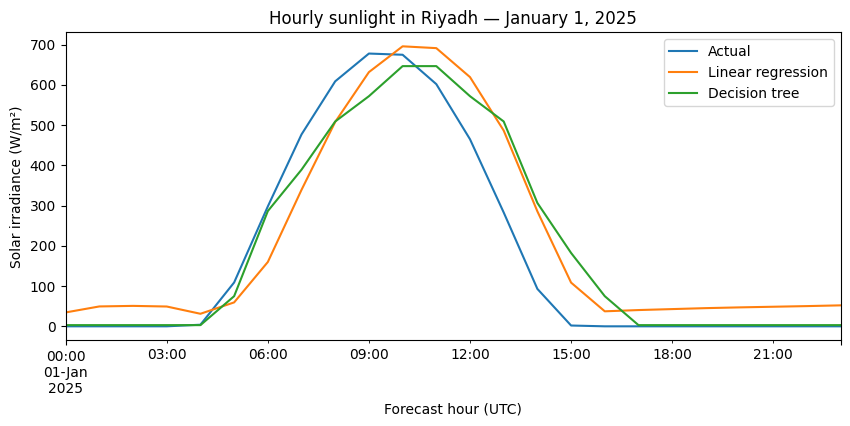

In [438]:
import matplotlib.pyplot as plt

riyadh = test_data["city"] == "Riyadh"
one_day = comparison.loc[riyadh].head(24).copy()

one_day["Decision tree"] = pd.Series(tree_pred, index=test_data.index)
one_day.index = target_time.loc[one_day.index]

one_day.columns = ["Actual", "Linear regression", "Decision tree"]
one_day.plot(figsize=(10, 4))
plt.title("Hourly sunlight in Riyadh — January 1, 2025")
plt.xlabel("Forecast hour (UTC)")
plt.ylabel("Solar irradiance (W/m²)")
plt.show()


## 24. Create a feature for the change in sunlight

We calculate how much sunlight has increased or decreased since the previous hour in the same city. We also add the forecast hour and two features that represent the hour as a repeating 24-hour cycle.


In [439]:
import numpy as np

df["sunlight_change"] = df.groupby("city")["shortwave_radiation"].diff()

df["forecast_hour"] = (df["time"].dt.hour + 1) % 24
df["hour_sin"] = np.sin(2 * np.pi * df["forecast_hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["forecast_hour"] / 24)

display(df[["city", "time", "shortwave_radiation", "sunlight_change", "forecast_hour"]].head(8))


,city,time,shortwave_radiation,sunlight_change,forecast_hour
0,Abha,2020-01-01 00:00:00+00:00,0.0,NaN,1
1,Abha,2020-01-01 01:00:00+00:00,0.0,0.0,2
2,Abha,2020-01-01 02:00:00+00:00,0.0,0.0,3
3,Abha,2020-01-01 03:00:00+00:00,0.0,0.0,4
4,Abha,2020-01-01 04:00:00+00:00,3.0,3.0,5
5,Abha,2020-01-01 05:00:00+00:00,134.0,131.0,6
6,Abha,2020-01-01 06:00:00+00:00,362.0,228.0,7
7,Abha,2020-01-01 07:00:00+00:00,570.0,208.0,8


## 25. Split the data for the feature experiment

We train on 2020–2023 and use 2024 to compare the original inputs with the expanded set.

In [440]:
validation_year = 2024

feature_train = df[target_time.dt.year < validation_year]
validation = df[target_time.dt.year == validation_year]

print("Training rows:", len(feature_train))
print("Validation rows:", len(validation))

Training rows: 280504
Validation rows: 70272


## 26. Check which features are related to next-hour sunlight

We use the 2020–2023 data to measure the correlation between each candidate input and next-hour sunlight.

In [441]:
candidate_features = weather + solar + ["sunlight_change"]
target = feature_train["next_hour_sunlight"]

correlations = feature_train[candidate_features].corrwith(target)
display(correlations.round(3).to_frame("Correlation with next-hour sunlight"))

,Correlation with next-hour sunlight
temperature_2m,0.340
relative_humidity_2m,-0.332
dew_point_2m,-0.109
surface_pressure,-0.011
wind_speed_10m,0.130
wind_direction_10m,-0.038
cloud_cover,-0.074
precipitation,-0.006
shortwave_radiation,0.943
direct_radiation,0.931


## 27. Test each feature on its own

We train a separate decision tree for each candidate feature and compare their errors on the same 2024 data. Each tree uses only one input.

In [442]:
experiment_train = feature_train.dropna(subset=candidate_features)
scores = []

for feature in candidate_features:
    single_tree = DecisionTreeRegressor(max_depth=8, random_state=42)
    single_tree.fit(experiment_train[[feature]], experiment_train["next_hour_sunlight"])

    predictions = single_tree.predict(validation[[feature]])
    error = mean_absolute_error(validation["next_hour_sunlight"], predictions)
    scores.append([feature, error])

feature_results = pd.DataFrame(scores, columns=["Only input used", "2024 MAE (W/m²)"])
display(feature_results.sort_values("2024 MAE (W/m²)").round(2))

,Only input used,2024 MAE (W/m²)
8,shortwave_radiation,71.05
9,direct_radiation,72.67
11,direct_normal_irradiance,85.76
10,diffuse_radiation,93.57
12,sunlight_change,121.80
1,relative_humidity_2m,256.79
0,temperature_2m,256.89
3,surface_pressure,268.32
4,wind_speed_10m,276.69
5,wind_direction_10m,278.22


## 28. Find the best second input

Current sunlight was our strongest single input. We pair it with each remaining feature and compare the average forecast error on the same 2024 data.

In [443]:
first_input = "shortwave_radiation"
pair_scores = []

for second_input in candidate_features:
    if second_input == first_input:
        continue

    inputs = [first_input, second_input]
    pair_tree = DecisionTreeRegressor(max_depth=8, random_state=42)
    pair_tree.fit(experiment_train[inputs], experiment_train["next_hour_sunlight"])

    predictions = pair_tree.predict(validation[inputs])
    error = mean_absolute_error(validation["next_hour_sunlight"], predictions)
    pair_scores.append([second_input, error])

pair_results = pd.DataFrame(pair_scores, columns=["Second input", "2024 MAE (W/m²)"])
display(pair_results.sort_values("2024 MAE (W/m²)").round(2))

,Second input,2024 MAE (W/m²)
11,sunlight_change,15.66
4,wind_speed_10m,61.00
0,temperature_2m,61.69
1,relative_humidity_2m,64.73
3,surface_pressure,67.84
10,direct_normal_irradiance,68.64
9,diffuse_radiation,69.05
2,dew_point_2m,69.15
8,direct_radiation,69.32
6,cloud_cover,69.34


In [444]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

def evaluate_forecast(y_true, y_pred, label="Model"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # 1. All-hours metrics
    overall_mae = mean_absolute_error(y_true, y_pred)
    overall_rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # 2. Daytime-only metrics (excludes trivial 0-actual & 0-predicted night hours)
    day_mask = y_true > 0
    day_mae = mean_absolute_error(y_true[day_mask], y_pred[day_mask])
    day_rmse = np.sqrt(mean_squared_error(y_true[day_mask], y_pred[day_mask]))

    print(f"=== {label} ===")
    print(f"Overall (24h) -> MAE: {overall_mae:6.2f} W/m² | RMSE: {overall_rmse:6.2f} W/m²")
    print(f"Daytime Only  -> MAE: {day_mae:6.2f} W/m² | RMSE: {day_rmse:6.2f} W/m² (n={day_mask.sum():,} hrs)\n")

# Compare Persistence Baseline vs. 3-Feature Tree on 2024 Validation
features = ["shortwave_radiation", "sunlight_change", "direct_normal_irradiance"]

# Correcting the variables to feature_train, validation, and 'next_hour_sunlight' based on earlier cell setup
tree_val = DecisionTreeRegressor(max_depth=8, random_state=42)
tree_val.fit(feature_train[features], feature_train["next_hour_sunlight"])
val_preds = tree_val.predict(validation[features])

evaluate_forecast(validation["next_hour_sunlight"], validation["shortwave_radiation"], label="2024 Val: Persistence Baseline")
evaluate_forecast(validation["next_hour_sunlight"], val_preds, label="2024 Val: Depth-8 Tree (3 Features)")

=== 2024 Val: Persistence Baseline ===
Overall (24h) -> MAE:  71.30 W/m² | RMSE: 109.71 W/m²
Daytime Only  -> MAE: 131.73 W/m² | RMSE: 149.91 W/m² (n=37,502 hrs)

=== 2024 Val: Depth-8 Tree (3 Features) ===
Overall (24h) -> MAE:  14.95 W/m² | RMSE:  35.04 W/m²
Daytime Only  -> MAE:  26.14 W/m² | RMSE:  47.92 W/m² (n=37,502 hrs)




### 29. Test a third input for the decision tree

In a separate weather-input experiment, we kept current sunlight and wind speed and tested each remaining weather variable as a third input.

Temperature achieved the lowest 2024 MAE at 56.06 W/m², followed by relative humidity at 57.39 W/m². Both improved the two-input model, although the improvement was relatively small.


In [445]:
scores = []
for candidate in weather:
    if candidate == "wind_speed_10m":
        continue

    inputs = ["shortwave_radiation", "wind_speed_10m", candidate]
    trial_tree = DecisionTreeRegressor(max_depth=8, random_state=42)
    trial_tree.fit(experiment_train[inputs], experiment_train["next_hour_sunlight"])

    predictions = trial_tree.predict(validation[inputs])
    error = mean_absolute_error(validation["next_hour_sunlight"], predictions)
    scores.append([candidate, error])

results_29 = pd.DataFrame(scores, columns=["Third input", "2024 MAE (W/m²)"])
display(results_29.sort_values("2024 MAE (W/m²)").round(2))

,Third input,2024 MAE (W/m²)
0,temperature_2m,56.06
1,relative_humidity_2m,57.39
3,surface_pressure,58.10
4,wind_direction_10m,59.54
5,cloud_cover,59.62
2,dew_point_2m,60.09
6,precipitation,60.56



## 30. Compare feature combinations and tree depths

We test two starting sets of 3 and 13 inputs, adding different combinations of latitude, longitude, and the forecast hour.

We also compare depths of 5, 8, 10, and 12, giving us 64 configurations. We use the 2024 validation MAE to select the best combination before testing it on 2025.

We then test whether adding the hour and location improves linear regression.


In [446]:

from itertools import combinations

three_inputs = ["shortwave_radiation", "sunlight_change", "cloud_cover"]
extra_features = ["latitude", "longitude", "forecast_hour"]

results = []

for base in [three_inputs, candidate_features]:
    for n in range(4):
        for extra in combinations(extra_features, n):
            inputs = base + list(extra)

            for depth in [5, 8, 10, 12]:
                tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
                tree.fit(experiment_train[inputs], experiment_train["next_hour_sunlight"])

                predictions = tree.predict(validation[inputs])
                mae = mean_absolute_error(validation["next_hour_sunlight"], predictions)

                results.append([inputs, depth, mae])

results_df = pd.DataFrame(results, columns=["Features", "Depth", "MAE"])
results_df = results_df.sort_values("MAE").reset_index(drop=True)

print("Top 10 combinations:")
display(results_df.head(10).round(2))

tree_features = results_df.loc[0, "Features"]
best_depth = int(results_df.loc[0, "Depth"])

print("\nBest depth:", best_depth)
print("Best features:", tree_features)
print("Lowest 2024 MAE:", round(results_df.loc[0, "MAE"], 2), "W/m²")
print("Configurations tested:", len(results_df))


Top 10 combinations:


,Features,Depth,MAE
0,"[temperature_2m, relative_humidity_2m, dew_poi...",12,10.63
1,"[temperature_2m, relative_humidity_2m, dew_poi...",12,10.64
2,"[temperature_2m, relative_humidity_2m, dew_poi...",12,10.75
3,"[temperature_2m, relative_humidity_2m, dew_poi...",12,10.85
4,"[shortwave_radiation, sunlight_change, cloud_c...",12,10.96
5,"[shortwave_radiation, sunlight_change, cloud_c...",12,10.97
6,"[shortwave_radiation, sunlight_change, cloud_c...",12,11.06
7,"[shortwave_radiation, sunlight_change, cloud_c...",12,11.34
8,"[temperature_2m, relative_humidity_2m, dew_poi...",10,11.47
9,"[temperature_2m, relative_humidity_2m, dew_poi...",10,11.49



Best depth: 12
Best features: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m', 'cloud_cover', 'precipitation', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'sunlight_change', 'longitude', 'forecast_hour']
Lowest 2024 MAE: 10.63 W/m²
Configurations tested: 64


In [447]:

linear_options = {
    "13 features": candidate_features,
    "13 + hour": candidate_features + ["hour_sin", "hour_cos"],
    "13 + hour + location": candidate_features + ["hour_sin", "hour_cos", "latitude", "longitude"]
}

linear_scores = []

for name, inputs in linear_options.items():
    model = LinearRegression()
    model.fit(experiment_train[inputs], experiment_train["next_hour_sunlight"])

    predictions = model.predict(validation[inputs]).clip(0)
    mae = mean_absolute_error(validation["next_hour_sunlight"], predictions)

    linear_scores.append([name, mae, inputs])

linear_results = pd.DataFrame(linear_scores, columns=["Features used", "2024 MAE", "Inputs"])
linear_results = linear_results.sort_values("2024 MAE").reset_index(drop=True)

display(linear_results[["Features used", "2024 MAE"]].round(2))

best_linear_features = linear_results.loc[0, "Inputs"]
print("Best linear regression features:", best_linear_features)


,Features used,2024 MAE
0,13 + hour + location,23.35
1,13 + hour,23.39
2,13 features,29.32


Best linear regression features: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m', 'cloud_cover', 'precipitation', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'sunlight_change', 'hour_sin', 'hour_cos', 'latitude', 'longitude']



## 31. Evaluate the decision tree on the 2025 test data

We train the decision tree using the features and depth selected from our 2024 experiments. We then predict next-hour radiation for all eight cities in 2025.

We also compare it with a smaller tree using only four inputs: current radiation, change in radiation, cloud cover, and forecast hour. This helps us see how much accuracy we lose when using fewer inputs.


In [448]:

final_train = df.loc[train_data.index].dropna(subset=["sunlight_change"])
final_test = df.loc[test_data.index]

final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
final_tree.fit(final_train[tree_features], final_train["next_hour_sunlight"])

final_predictions = final_tree.predict(final_test[tree_features])
final_mae = mean_absolute_error(final_test["next_hour_sunlight"], final_predictions)

compact_features = ["shortwave_radiation", "sunlight_change", "cloud_cover", "forecast_hour"]

compact_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
compact_tree.fit(final_train[compact_features], final_train["next_hour_sunlight"])

compact_predictions = compact_tree.predict(final_test[compact_features])
compact_mae = mean_absolute_error(final_test["next_hour_sunlight"], compact_predictions)

print("Full tree:", len(tree_features), "features")
print("2025 MAE:", round(final_mae, 2), "W/m²")

print("\nSmaller tree:", len(compact_features), "features")
print("2025 MAE:", round(compact_mae, 2), "W/m²")


Full tree: 15 features
2025 MAE: 9.69 W/m²

Smaller tree: 4 features
2025 MAE: 10.3 W/m²



## 32. Compare linear regression and the decision tree

We train linear regression using the features selected from our 2024 experiments. Both models use 2020–2024 training data and are tested on the same 2025 data.

We compare their MAE, RMSE, R², and the percentage of predictions within ±50 W/m² of the actual value. The model with the lower MAE has the smaller average prediction error.


In [449]:

final_linear = LinearRegression()
final_linear.fit(final_train[best_linear_features], final_train["next_hour_sunlight"])

linear_predictions = final_linear.predict(final_test[best_linear_features]).clip(0)
linear_mae = mean_absolute_error(final_test["next_hour_sunlight"], linear_predictions)

print("Linear regression 2025 MAE:", round(linear_mae, 2), "W/m²")
print("Decision tree 2025 MAE:", round(final_mae, 2), "W/m²")
print("Linear regression features:", best_linear_features)

actual = final_test["next_hour_sunlight"].to_numpy()

for name, predictions in [("Linear regression", linear_predictions),
                          ("Decision tree", final_predictions)]:
    rmse = mean_squared_error(actual, predictions) ** 0.5
    r2 = r2_score(actual, predictions)
    within_50 = (abs(actual - predictions) <= 50).mean() * 100

    print(f"\n{name}")
    print("RMSE:", round(rmse, 2))
    print("R²:", round(r2, 3))
    print("Predictions within ±50 W/m²:", round(within_50, 1), "%")


Linear regression 2025 MAE: 22.8 W/m²
Decision tree 2025 MAE: 9.69 W/m²
Linear regression features: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m', 'cloud_cover', 'precipitation', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'sunlight_change', 'hour_sin', 'hour_cos', 'latitude', 'longitude']

Linear regression
RMSE: 39.24
R²: 0.986
Predictions within ±50 W/m²: 88.6 %

Decision tree
RMSE: 26.6
R²: 0.993
Predictions within ±50 W/m²: 95.9 %


## 33. Compare the two models in each city

We use the 2025 predictions from both models to calculate their MAE in each city. We compare the scores side by side and sort the cities from lowest to highest decision tree MAE.

In [450]:
city_errors = final_test[["city"]].copy()
actual = final_test["next_hour_sunlight"]

city_errors["Decision tree MAE"] = (actual - final_predictions).abs()
city_errors["Linear regression MAE"] = (actual - linear_predictions).abs()

city_mae = city_errors.groupby("city").mean()
city_mae = city_mae.sort_values("Decision tree MAE")
display(city_mae.round(2))

,Decision tree MAE,Linear regression MAE
city,,
Sakaka,7.32,19.80
Tabuk,7.50,21.14
Jeddah,8.21,19.95
Medina,8.77,22.42
Riyadh,8.81,21.27
Dammam,8.93,19.75
Najran,12.61,27.55
Abha,15.39,30.54


## 34. Compare prediction errors across cities

We plot the 2025 mean absolute error for both models in each city. Each pair of bars represents one city. A shorter bar means the model predicted next-hour radiation more accurately on average.

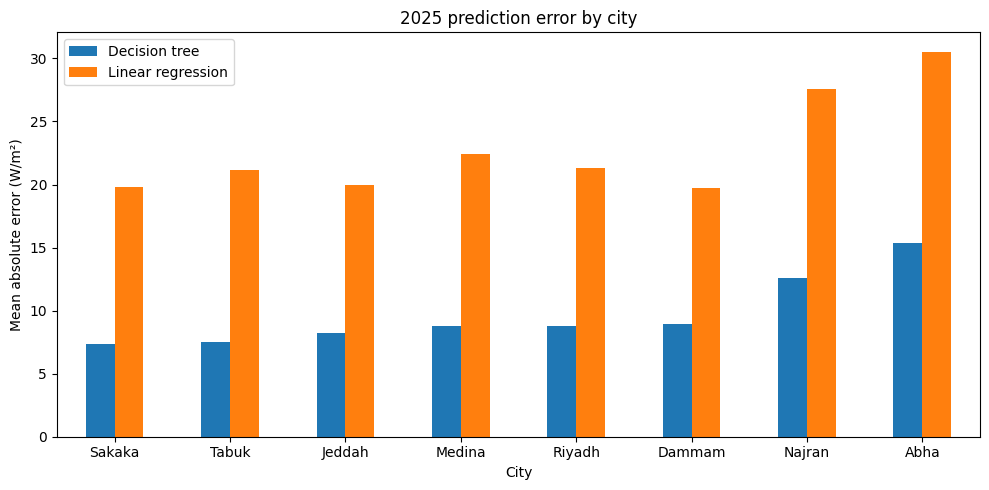

In [451]:
city_mae.plot.bar(figsize=(10, 5), rot=0)
plt.title("2025 prediction error by city")
plt.xlabel("City")
plt.ylabel("Mean absolute error (W/m²)")
plt.legend(["Decision tree", "Linear regression"])
plt.tight_layout()
plt.show()


## 35. Compare hourly radiation predictions on January 7, 2025

We compare the Open-Meteo radiation values with both models' predictions for one day in Riyadh, Dammam, Abha, and Najran. All four plots use the same scale. The closer a prediction is to the black line, the smaller its error.

We also compare the models using confusion matrices. We divide radiation into four categories: near zero (0–10), low (10–200), medium (200–600), and high (above 600 W/m²).

The matrices show the percentage of observations classified into each category. Since both models predict numerical values, we still use MAE as our main evaluation metric.


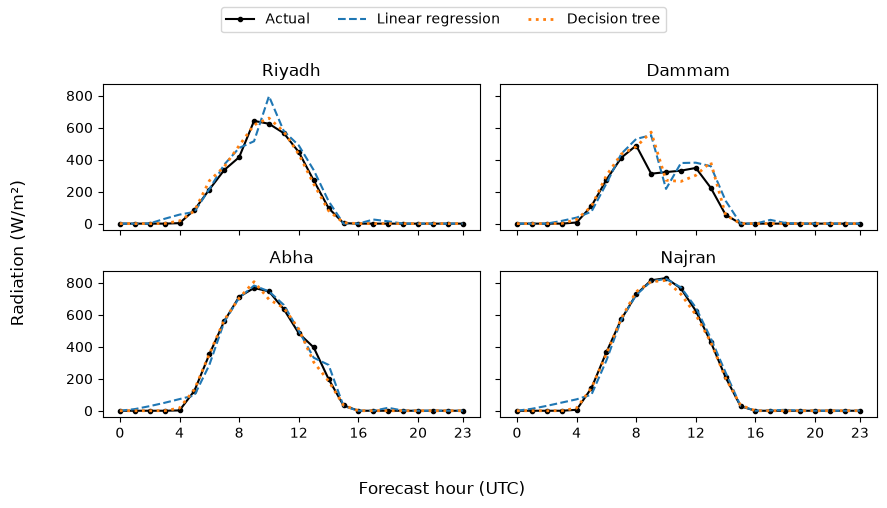

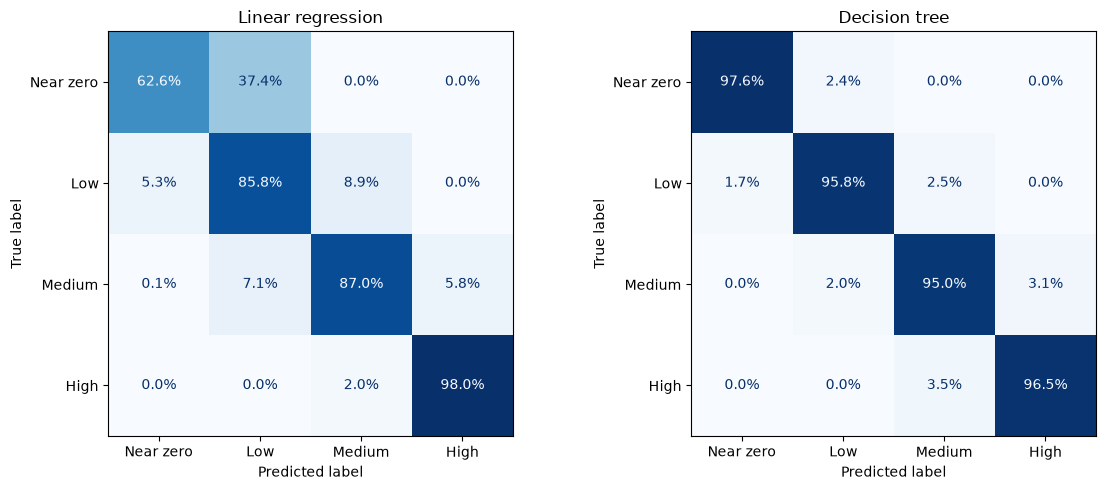

In [452]:
# Reconstruct plot_data using the 2025 test dataset and predictions
from sklearn.metrics import ConfusionMatrixDisplay

plot_data = final_test.copy()
plot_data["Linear regression"] = linear_predictions
plot_data["Decision tree"] = final_predictions

plot_data["forecast_time"] = target_time.loc[plot_data.index]

day = plot_data[(plot_data["forecast_time"] >= "2025-01-07") &
                (plot_data["forecast_time"] < "2025-01-08")]

fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True, sharey=True)
cities = ["Riyadh", "Dammam", "Abha", "Najran"]

for ax, city in zip(axes.flat, cities):
    data = day[day["city"] == city]
    hour = data["forecast_time"].dt.hour

    ax.plot(hour, data["next_hour_sunlight"], "k.-", label="Actual")
    ax.plot(hour, data["Linear regression"], "C0--", label="Linear regression")
    ax.plot(hour, data["Decision tree"], "C1:", linewidth=2, label="Decision tree")
    ax.set_title(city)
    ax.set_xticks([0, 4, 8, 12, 16, 20, 23])

fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=3)
fig.supxlabel("Forecast hour (UTC)")
fig.supylabel("Radiation (W/m²)")
plt.tight_layout(rect=[0.03, 0.03, 1, 0.91])
plt.show()

bins = [-1, 10, 200, 600, float("inf")]
labels = ["Near zero", "Low", "Medium", "High"]

actual = pd.cut(final_test["next_hour_sunlight"], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in zip(
    axes,
    ["Linear regression", "Decision tree"],
    [linear_predictions, final_predictions]
):
    predicted = pd.cut(predictions.clip(0), bins=bins, labels=labels)

    ConfusionMatrixDisplay.from_predictions(
        actual, predicted,
        labels=labels,
        normalize="true",
        values_format=".1%",
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [453]:

from sklearn.metrics import classification_report

bins = [-1, 10, 200, 600, float("inf")]
labels = ["Near zero", "Low", "Medium", "High"]

actual_classes = pd.cut(final_test["next_hour_sunlight"], bins=bins, labels=labels)

for name, predictions in [("Linear regression", linear_predictions),
                          ("Decision tree", final_predictions)]:

    predicted_classes = pd.cut(predictions.clip(0), bins=bins, labels=labels)

    print(f"\n{name}")
    print(classification_report(
        actual_classes, predicted_classes,
        labels=labels, digits=3, zero_division=0
    ))



Linear regression
              precision    recall  f1-score   support

   Near zero      0.980     0.626     0.764     34840
         Low      0.333     0.858     0.479      8084
      Medium      0.914     0.870     0.892     12338
        High      0.953     0.980     0.966     14818

    accuracy                          0.771     70080
   macro avg      0.795     0.834     0.775     70080
weighted avg      0.888     0.771     0.797     70080


Decision tree
              precision    recall  f1-score   support

   Near zero      0.996     0.976     0.986     34840
         Low      0.879     0.958     0.917      8084
      Medium      0.941     0.950     0.945     12338
        High      0.974     0.965     0.969     14818

    accuracy                          0.967     70080
   macro avg      0.948     0.962     0.954     70080
weighted avg      0.968     0.967     0.967     70080




### What the plots show

On January 7, both models followed the daily rise and fall in radiation, although their predictions differed around sunrise and sudden changes in radiation.

The decision tree performed better in most categories. It correctly classified 97.6% of near-zero observations and 95.8% of low-radiation observations, compared with 62.6% and 85.8% for linear regression.

Linear regression was slightly better at classifying high radiation (98.0% vs 96.5%), but the decision tree had a lower overall MAE of 9.69 W/m², compared with 22.80 W/m² for linear regression.


## 36. Compare current and next-hour radiation across eight cities

Current radiation had the lowest 2024 validation error when we tested each input on its own. We plot it against next-hour radiation for each city in the 2025 test data. Each dot represents one hour. A dot above the diagonal means radiation increased in the next hour. A dot below it means radiation decreased.

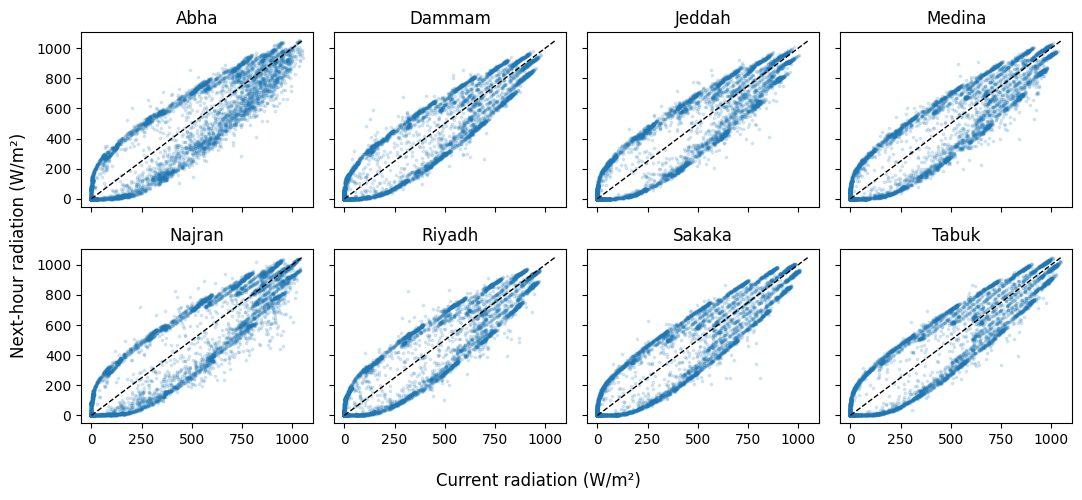

In [454]:
cities = sorted(final_test["city"].unique())
limit = final_test[["shortwave_radiation", "next_hour_sunlight"]].max().max()

fig, axes = plt.subplots(2, 4, figsize=(11, 5), sharex=True, sharey=True)

for ax, city in zip(axes.flat, cities):
    data = final_test[final_test["city"] == city]
    ax.scatter(data["shortwave_radiation"], data["next_hour_sunlight"],
               s=3, alpha=0.15)
    ax.plot([0, limit], [0, limit], "k--", linewidth=1)
    ax.set_title(city)

fig.supxlabel("Current radiation (W/m²)")
fig.supylabel("Next-hour radiation (W/m²)")
plt.tight_layout()
plt.show()

## 37. Estimate solar electricity generation in each city

We use the decision tree’s hourly radiation predictions to estimate how much electricity one horizontal 400 W panel would generate in each city in 2025. We assume 20% system losses in every city. We add the hourly estimates and rank all eight cities by total electricity generated in kWh. The first three cities have the highest estimated output.

In [455]:
panel_kw = 0.4
system_loss = 0.20

solar_output = final_test[["city"]].copy()
solar_output["Estimated kWh"] = (final_predictions / 1000) * panel_kw * (1 - system_loss)

city_output = solar_output.groupby("city")["Estimated kWh"].sum()
display(city_output.sort_values(ascending=False).round(1))

,Estimated kWh
city,
Najran,745.0
Tabuk,723.2
Abha,720.3
Medina,711.7
Jeddah,695.5
Sakaka,682.4
Riyadh,680.3
Dammam,663.6


## 38. Compare estimated solar electricity output from 2020 to 2025

We use hourly Open-Meteo radiation data and the same panel assumptions to estimate yearly electricity output for each city. We compare all six years to see whether the same cities usually lead and whether their output shows a consistent trend.

In [456]:
history = df[["city", "time", "shortwave_radiation"]].copy()
history["year"] = history["time"].dt.year
history["Estimated kWh"] = history["shortwave_radiation"] / 1000 * panel_kw * (1 - system_loss)

yearly_output = history.pivot_table(
    index="year", columns="city", values="Estimated kWh", aggfunc="sum"
)

display(yearly_output.round(1))

city,Abha,Dammam,Jeddah,Medina,Najran,Riyadh,Sakaka,Tabuk
year,,,,,,,,
2020,708.9,660.3,701.6,712.4,736.6,679.5,675.4,720.9
2021,718.1,674.6,692.3,701.3,751.9,688.7,683.4,725.7
2022,711.5,666.4,698.4,715.9,737.8,686.1,675.4,723.4
2023,702.3,654.6,690.9,704.8,722.1,673.1,667.6,716.1
2024,693.7,662.7,693.3,709.1,719.7,678.4,680.0,729.3
2025,723.8,660.2,697.2,711.7,745.5,680.1,682.3,727.5



## 39. Would solar pay for itself by 2030?

We estimate bill savings for 400 W of rooftop solar installed at the start of 2027. We use the average output for Najran, Tabuk, and Abha from 2020–2025 because the data show no consistent yearly increase.

We assume the household uses all the electricity generated, the electricity rate stays at SAR 0.21/kWh, and installation costs SAR 1,000. We calculate four years of savings and the time needed to recover the installation cost.

This is a projection based on historical averages, not a prediction from our machine learning models. It also excludes maintenance and financing costs.


In [457]:
annual_kwh = yearly_output[["Najran", "Tabuk", "Abha"]].mean()
annual_savings = annual_kwh * 0.21
installed_cost = 1000

results = pd.DataFrame({
    "Annual savings (SAR)": annual_savings,
    "Savings by end of 2030 (SAR)": annual_savings * 4,
    "Payback (years)": installed_cost / annual_savings
})

display(results.round(1))

,Annual savings (SAR),Savings by end of 2030 (SAR),Payback (years)
city,,,
Najran,154.5,617.9,6.5
Tabuk,152.0,608.0,6.6
Abha,149.0,596.2,6.7



## 40. Project conclusion

We predicted next-hour solar radiation across eight Saudi cities using hourly Open-Meteo reanalysis data. We started with three inputs, then tested additional weather variables and the change in radiation from the previous hour.

We also compared different feature combinations and tree depths using the 2024 validation data. Adding the forecast hour improved both models, and depth 12 performed best among the depths tested.

On the 2025 test data, the decision tree achieved an MAE of 9.69 W/m², compared with 22.80 W/m² for linear regression. The tree also had a lower error in every city.

We tested a smaller decision tree using only four inputs. It achieved an MAE of 10.30 W/m², only slightly higher than the full model. This shows that we can still make accurate one-hour predictions without needing all the weather variables.

Estimated solar electricity output showed no consistent increase from 2020 to 2025, so we used each city's six-year average to estimate future savings. For a 400 W panel installed at the start of 2027, estimated savings by the end of 2030 were SAR 617.9 in Najran, SAR 608.0 in Tabuk, and SAR 596.2 in Abha.

Under our assumptions, all three cities would recover about 60% of the SAR 1,000 installation cost by the end of 2030. If annual savings continued at the same rate, the panel would pay for itself during 2033. Najran had the shortest estimated payback at 6.5 years, followed by Tabuk at 6.6 and Abha at 6.7.


## Notes
- Data is Open-Meteo reanalysis/model output, **not** ground measurements. State this in the report.
- If a check looks wrong (missing hours, night GHI, out-of-range values), investigate before cleaning.